# Unidades 22, 23 y 24: Pila, Cola, Búsqueda secuencial y Binaria.

## Unidad 22: Pila (`Stack`)

### 22.1 Qué es una pila

La pila es un tipo de datos abstracto en el que un elemento sólo se puede añadir o eliminar en un lado de la parte
superior.

Este tipo de datos funciona por el método LIFO (Last-In-First-Out) en el que se puede eliminar primero el
elemento que previamente se introdujo muy al final.

| Operación | Qué hace |
|---|---|
| `push(item)` | Agrega `item` en la cima |
| `pop()` | Quita y **devuelve** el elemento de la cima |
| `is_empty()` | Dice si la pila está vacía |

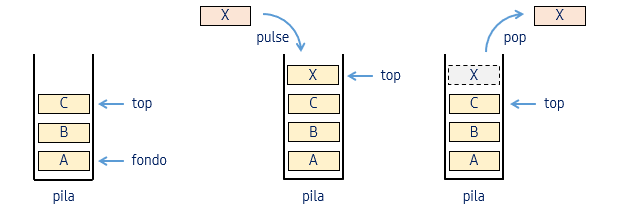

### 22.2 Una pila con una lista de Python

**Problema:** ver las operaciones funcionando con lo que ya conocemos.

Una lista ya sirve como pila si solo usamos el **final** como cima:

- `append(x)` hace de `push`.
- `pop()` hace de `pop`.
- `pila[-1]` **mira** la cima sin quitarla.
- Si la lista está vacía, `pop()` da `IndexError`: antes hay que comprobar que no esté vacía.

In [1]:
# Crear Pila

pila = []
print(pila)

print('-'*50)

pila.append('Estructura de datos') #añaden elementos
print(pila)
pila.append('TK1')
pila.append('TK2')
pila.append('TK3')
print(pila)

print('\nTope de la pila:',pila[-1])

print(pila.pop())
print(pila)
print(pila.pop())
print(pila)

print('\nTope de la pila:',pila[-1])

print(pila.pop())
print(pila)

print(pila.pop())
print(pila)

print(len(pila) == 0)

try:
  pila.pop()
  print(pila)
except IndexError as error:
  print("\nError:", error)

[]
--------------------------------------------------
['Estructura de datos']
['Estructura de datos', 'TK1', 'TK2', 'TK3']

Tope de la pila: TK3
TK3
['Estructura de datos', 'TK1', 'TK2']
TK2
['Estructura de datos', 'TK1']

Tope de la pila: TK1
TK1
['Estructura de datos']
Estructura de datos
[]
True

Error: pop from empty list


**Ejemplos de Uso en la vida real**

* El navegador web acumula en una pila las direcciones de las páginas web
visita das recientemente. Al visitar una nueva página, se acumulará en la
parte superior de la pila.
* Si el usuario hace clic en "atrás", se selecciona la dirección de la parte
superior de la pila, que mostrará el sitio web visitado anteriormente.

* Hay una funcion de deshacer en el editor de texto y en MS Word (esta función también acumula las operaciones de edición realizadas por el
usuario en una pila, y el 'deshacer' cancelara las operaciones en orden desde
la parte superior de la pila).

### 22.3 La clase `Stack`

**Problema:** usar una lista "a mano" obliga a recordar las reglas. Una clase las encierra y deja una pila lista para usar.

La clase usa lo aprendido en la unidad 21: `__init__` crea la lista interna (vacía) y cada operación es un método con `self`.

In [2]:
class Stack:
    def __init__(self):
        self.items = []                 # lista interna, vacía al crear la pila

    def push(self, item):
        self.items.append(item)

    def pop(self):
        if self.is_empty():
            raise IndexError("La pila esta vacia")
        return self.items.pop()

    def is_empty(self):
        return len(self.items) == 0

pila = Stack()
print(pila.is_empty())      # True
pila.push(10)
pila.push(20)
pila.push(30)
print(pila.pop())           # 30
print(pila.pop())           # 20
print(pila.is_empty())      # False: queda el 10

try:
    Stack().pop()
except IndexError as error:
    print("IndexError:", error)

True
30
20
False
IndexError: La pila esta vacia


**Ejemplo 2**

In [3]:
historial = []

# Navegar
historial.append("google.com")
historial.append("youtube.com")
historial.append("openai.com")
historial.append("canva.com")
historial.append("instagram.com")

print("Historial:", historial)

# Usuario presiona 'Atrás'
ultima = historial.pop()
print("Volviendo a:", ultima)
print("Historial ahora:", historial)

Historial: ['google.com', 'youtube.com', 'openai.com', 'canva.com', 'instagram.com']
Volviendo a: instagram.com
Historial ahora: ['google.com', 'youtube.com', 'openai.com', 'canva.com']


**Call Stack**

Cuando llamas a funciones en un programa, se almacenan en la pila de ejecución.

* Python internamente maneja esto, pero también se puede simular.

In [4]:
def f1():
    print("Entrando a f1")
    f2()
    print("Saliendo de f1")

def f2():
    print("Entrando a f2")
    f3()
    print("Saliendo de f2")

def f3():
    print("Entrando a f3")
    print("Saliendo de f3")

f1()

Entrando a f1
Entrando a f2
Entrando a f3
Saliendo de f3
Saliendo de f2
Saliendo de f1


## Unidad 23: Cola (`Queue`)

### 23.1 Qué es una cola

Una cola es un tipo de datos abstracto en el que **sólo es posible la eliminación en la parte delantera y sólo es posible la adición en la parte trasera.**

Dado que el primer elemento añadido también se elimina el primero, una cola es una estructura de datos que funciona con el método **FIFO (First-In-First-Out).**

**Una cola debe proporcionar dos interfaces importantes:**

* **enqueue:** añade un nuevo elemento al final de la cola
* **dequeue:** elimina un elemento de la parte delantera de la cola

| Operación | Qué hace |
|---|---|
| `enqueue(item)` | Agrega `item` al final |
| `dequeue()` | Quita y **devuelve** el elemento del frente |
| `is_empty()` | Dice si está vacía |
| `size()` | Dice cuántos elementos hay |

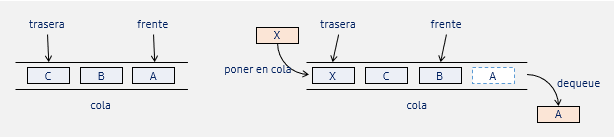

**Sintaxis**

In [5]:
from collections import deque

# Crear una cola

cola = deque()
print(cola)

cola.append('Carlos')
print(cola)
cola.appendleft('Ana')
print(cola)
cola.append('Luis')
print(cola)

print('-'*50)

persona = cola.popleft() # sacamos a una persona
print('Atendido:',persona)
print(cola)
persona = cola.popleft()
print('Atendido:',persona)
print(cola)

deque([])
deque(['Carlos'])
deque(['Ana', 'Carlos'])
deque(['Ana', 'Carlos', 'Luis'])
--------------------------------------------------
Atendido: Ana
deque(['Carlos', 'Luis'])
Atendido: Carlos
deque(['Luis'])


**NOTA:** Se usa append() para encolar y popleft() para desencolar (deque es lo más eficiente).

### 23.2 La clase `Queue`

**Problema:** igual que con la pila, encerrar las reglas en una clase.

Usamos una lista: se agrega al **final** con `append` y se quita del **frente** con `pop(0)`.

In [6]:
class Queue:
    def __init__(self):
        self.items = [] # creamos la lista vacia

    def enqueue(self, item):
        self.items.append(item)         # entra por el final

    def dequeue(self):
        if self.is_empty():
            raise IndexError("La cola esta vacia")
        return self.items.pop(0)      # sale por el frente

    def is_empty(self):
        return len(self.items) == 0

    def size(self):
        return len(self.items)

fila = Queue()
fila.enqueue("Ana")
fila.enqueue("Luis")
fila.enqueue("Marta")
print(fila.size())          # 3
print(fila.dequeue())       # Ana: la primera en llegar es la primera en salir
print(fila.dequeue())       # Luis
print(fila.size())          # 1

3
Ana
Luis
1


**Ejemplos de uso**

**Descargas en espera**

* Cuando descargas varios archivos, se encolan en orden.

* El primero que empezó se atiende primero.

In [7]:
# Ejemplo

from collections import deque

descargas = deque()
descargas.append('mp3')
descargas.append('archivos1.zip')

print(descargas)
descargas.popleft()

print(descargas)

deque(['mp3', 'archivos1.zip'])
deque(['archivos1.zip'])


## Unidad 24: Búsqueda secuencial

### 24.1 Qué es la búsqueda secuencial

La búsqueda secuencial es el algoritmo más simple para localizar un elemento en una lista, este consiste en recorrer uno por uno los elementos hasta encontrar el valor buscado o llegar al final.

Es directa, fácil de implementar y no requiere que la lista esté ordenada.
Esto la diferencia de la búsqueda binaria, que necesita datos previamente ordenados.

**Es útil cuando:**

* Los datos NO están ordenados (a diferencia de la binaria).

* La lista es pequeña o se busca una única vez.

* Se trabaja con estructuras en las que no se puede aplicar acceso directo ordenado (por ejemplo, leer registros de un archivo uno a uno).

In [8]:
def buscar(lista, objetivo):
    for indice in range(len(lista)):
        if lista[indice] == objetivo:
            return indice            # lo encontró: se detiene aquí
    return -1                        # recorrió todo y no estaba

numeros = [8, 3, 15, 6, 11]

print(buscar(numeros, 15))   # 2
print(buscar(numeros, 8))    # 0
print(buscar(numeros, 99))   # -1

2
0
-1


**Cuando usarla?**

**Ventajas / Cuándo usarla**

1. Cuando la lista no está ordenada.

2. Si la lista es pequeña (el costo de recorrerla no es grande).

3. Para búsquedas únicas o poco frecuentes.

4. En estructuras donde no se puede acceder aleatoriamente (ejemplo: leer registros de un archivo uno por uno).

**Desventajas / Cuándo evitarla**

1. En listas grandes, porque es lenta comparada con otros algoritmos (O(n)).

2. Si vas a hacer muchas búsquedas sobre la misma lista, conviene ordenarla primero y usar búsqueda binaria (O(log n)).



---



**Cual es la logica?**

1. Recorre la lista desde el índice 0 hasta el último.

2. En cada paso compara el valor de la posición actual con el objetivo x.

3. Si lo encuentra, retorna el índice.

4. Si llega al final sin hallarlo, devuelve -1.

In [9]:
# Codigo

def busqueda_secuencial(l_numeros, objetivo):
    for i in range(len(l_numeros)):
        print(f"indice={i}, valor={l_numeros[i]}")
        if l_numeros[i] == objetivo:
            return i
    return -1

num = [1,52,63,74,85,9,4,12,156,48235,785,1,0,2336,20]

pos = busqueda_secuencial(num,20)
print(f"\nEl numero esta en la posicion {pos}")

indice=0, valor=1
indice=1, valor=52
indice=2, valor=63
indice=3, valor=74
indice=4, valor=85
indice=5, valor=9
indice=6, valor=4
indice=7, valor=12
indice=8, valor=156
indice=9, valor=48235
indice=10, valor=785
indice=11, valor=1
indice=12, valor=0
indice=13, valor=2336
indice=14, valor=20

El numero esta en la posicion 14


## Unidad 25: Búsqueda Binaria

### 25.1 Qué es la búsqueda Binaria

La búsqueda binaria es un algoritmo eficiente que se utiliza para encontrar un elemento dentro de una lista ordenada.
La idea principal es dividir y conquistar:

Su finalidad es reducir drásticamente el número de comparaciones: en lugar de revisar uno por uno (búsqueda lineal, O(n)), divide el rango de búsqueda a la mitad en cada paso (O(log n)).

En lugar de revisar todos los elementos uno por uno (como en la búsqueda lineal), la lista se divide en mitades sucesivas hasta encontrar el elemento deseado o determinar que no existe.

**Se usa cuando:**

* Los datos están ordenados (o se pueden ordenar una vez y reutilizar).

* Necesitas consultas rápidas: encontrar usuarios por ID, ubicar un registro en un índice, validar si existe un valor, etc.

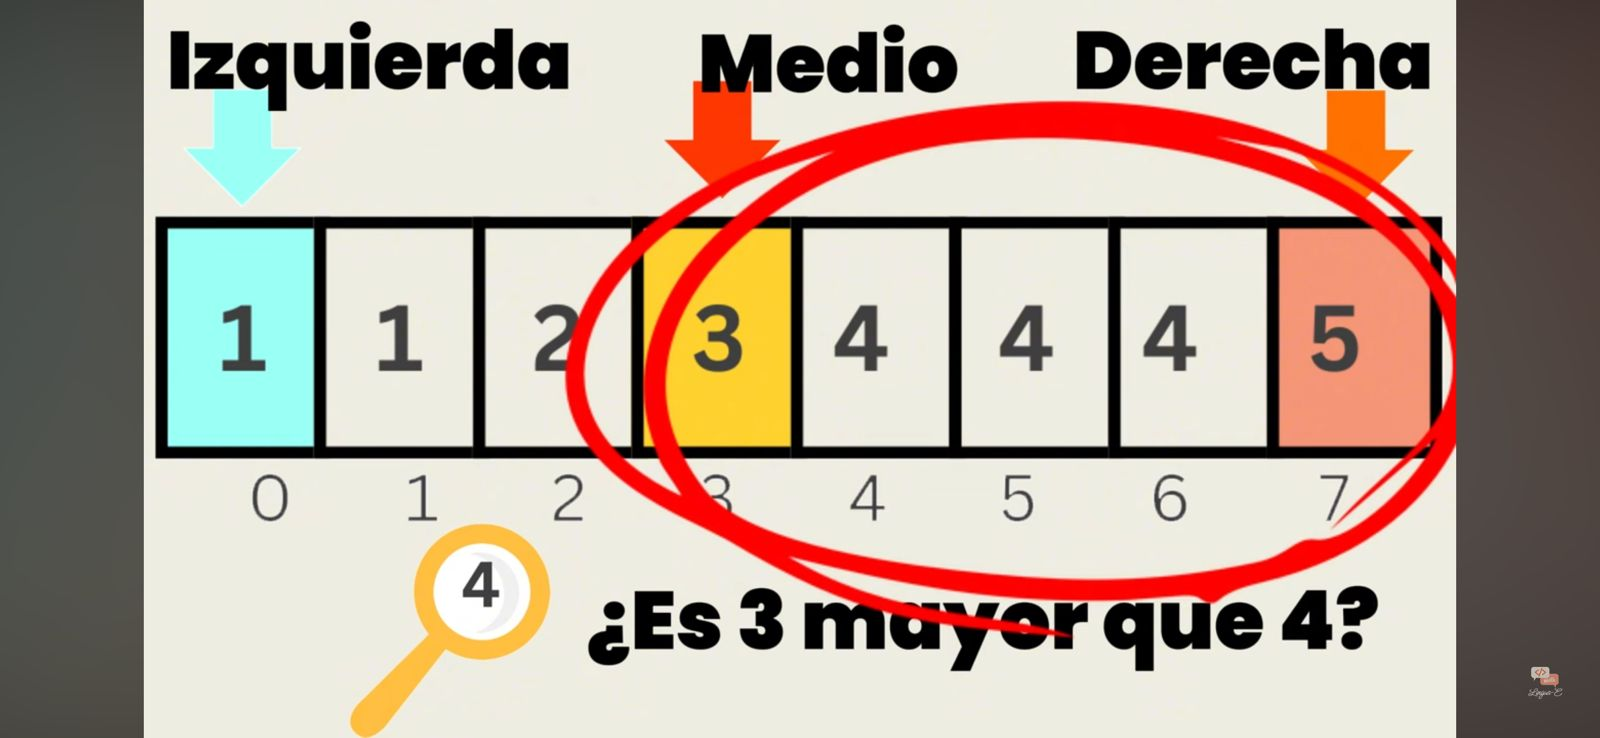



---



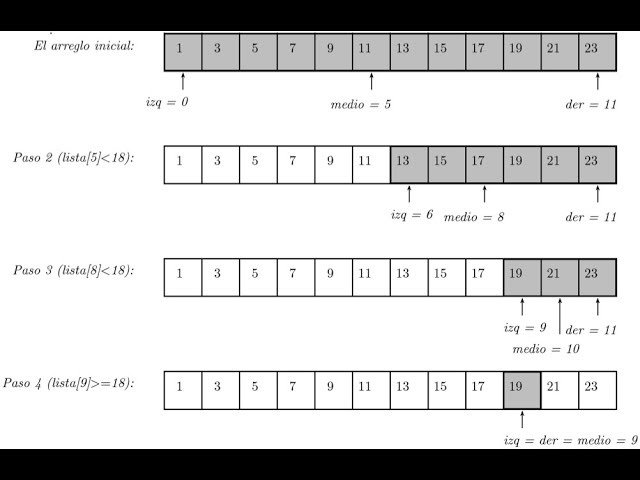

**Usos reales:**

* Bases de datos (buscar registros ordenados).

* Índices en motores de búsqueda.

* Validaciones en grandes volúmenes de datos (como logins en sistemas).

**Sintaxis Basica**

In [10]:
# Codigo

def bin_search(num, x):
    low, high = 0, len(num) -1
    while low <= high:
        mid = (low + high) // 2
        if num[mid] == x:
            return mid
        elif num[mid] > x:
            high = mid -1
        else:
            low = mid + 1
    return -1 # No lo consiguio

**La idea central (la lógica)**

Se trabaja con un rango marcado por dos índices: `low` (inicio) y `high` (fin).

1. Empieza con `low = 0` y `high = len(lista) - 1`.
2. Mientras `low <= high` (todavía queda rango por revisar):
   - Calcula el medio: `mid = (low + high) // 2`.
   - Si `lista[mid] == objetivo`: **encontrado**, devuelve `mid`.
   - Si `lista[mid] > objetivo`: el objetivo está a la **izquierda**, así que `high = mid - 1`.
   - Si `lista[mid] < objetivo`: el objetivo está a la **derecha**, así que `low = mid + 1`.
3. Si el bucle termina, el valor **no existe**: devuelve `-1`.


Repite mientras low <= high. Si el bucle termina sin encontrarlo, no existe (-1).

**Invariante mental útil**

> “Si x está en la lista, debe estar dentro del rango [low, high] actual.”
Cada iteración mantiene ese invariante y reduce el rango a la mitad.

**Nota:** En Python no hay problema de overflow, pero una forma segura de medio es mid = low + (high - low) // 2.

**Ejemplos**

In [11]:
S = [11, 17, 26, 28, 37, 45, 53, 59]
x = 45

pos = bin_search(S, x)

print(f"En S, {x} está en la posición {pos}.")

En S, 45 está en la posición 5.


In [12]:
clientes = [1001, 1020, 1035, 1044, 1070, 1100, 1200, 1350, 1400]
id_cliente = 1001
pos = bin_search(clientes, id_cliente)

if pos != -1:
    print(f"Cliente con ID {id_cliente} encontrado en la posición {pos}.")
else:
    print(f"Cliente con ID {id_cliente} no está registrado.")

Cliente con ID 1001 encontrado en la posición 0.


###**COMPARACION**

In [13]:
S = [11, 17, 26, 28, 37, 45, 53,2,59,15,74,85,63,1,5,8,4,3,9,52,741,85,9,766,2354,628,26384,624,712,325,7433,9852]
x = 712

print('-'*15, 'BUSQUEDA BINARIA', '-'*15,'\n')

def bin_search(nums, x):
    low, high = 0, len(nums) - 1
    while low <= high:
        mid = (low + high) // 2
        print(f"Buscando en rango [{low}, {high}], mid = {mid}")
        if nums[mid] == x:
            return mid
        elif nums[mid] > x:
            high = mid - 1
        else:
            low = mid + 1
    return -1


print("\nPosición encontrada:", bin_search(S, x))

print('\n','-'*15, 'BUSQUEDA SECUENCIAL', '-'*15,'\n')

def seq_search(nums, x):
    for i in range(len(nums)):
        print(f"índice={i}, valor={nums[i]}")
        if nums[i] == x:
            return i
    return -1


pos = seq_search(S,x)
print("\nPosición encontrada:", pos)

--------------- BUSQUEDA BINARIA --------------- 

Buscando en rango [0, 31], mid = 15
Buscando en rango [16, 31], mid = 23
Buscando en rango [16, 22], mid = 19
Buscando en rango [20, 22], mid = 21
Buscando en rango [22, 22], mid = 22

Posición encontrada: -1

 --------------- BUSQUEDA SECUENCIAL --------------- 

índice=0, valor=11
índice=1, valor=17
índice=2, valor=26
índice=3, valor=28
índice=4, valor=37
índice=5, valor=45
índice=6, valor=53
índice=7, valor=2
índice=8, valor=59
índice=9, valor=15
índice=10, valor=74
índice=11, valor=85
índice=12, valor=63
índice=13, valor=1
índice=14, valor=5
índice=15, valor=8
índice=16, valor=4
índice=17, valor=3
índice=18, valor=9
índice=19, valor=52
índice=20, valor=741
índice=21, valor=85
índice=22, valor=9
índice=23, valor=766
índice=24, valor=2354
índice=25, valor=628
índice=26, valor=26384
índice=27, valor=624
índice=28, valor=712

Posición encontrada: 28




---



# FIN

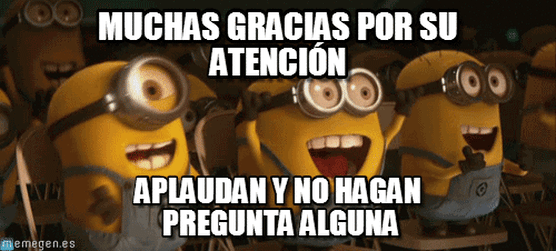